# AICS-202 | Laboratory 03
## Training Data Poisoning and Dataset Integrity
Course module: 3 | Suggested duration: 4 hours

**Objective:** measure how deliberately corrupted labels in a local training dataset affect a supervised model. This lab never changes external datasets or services.

**Scope:** simple random label corruption is an introductory poisoning simulation, not a realistic targeted backdoor.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
digits = load_digits()
X = digits.data.astype(float) / 16.0
y = digits.target.astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

def build_model(train_features, train_labels):
    model = LogisticRegression(max_iter=600, random_state=SEED)
    model.fit(train_features, train_labels)
    return model

model = build_model(X_train, y_train)
print('Dataset:', X.shape, '| Train:', len(X_train), '| Test:', len(X_test))
print('Clean test accuracy:', round(accuracy_score(y_test, model.predict(X_test)), 4))

Dataset: (1797, 64) | Train: 1347 | Test: 450
Clean test accuracy: 0.9622


Corruption 0%: 0 labels changed | Clean test accuracy 0.962
Corruption 5%: 67 labels changed | Clean test accuracy 0.960
Corruption 10%: 135 labels changed | Clean test accuracy 0.958
Corruption 20%: 269 labels changed | Clean test accuracy 0.933


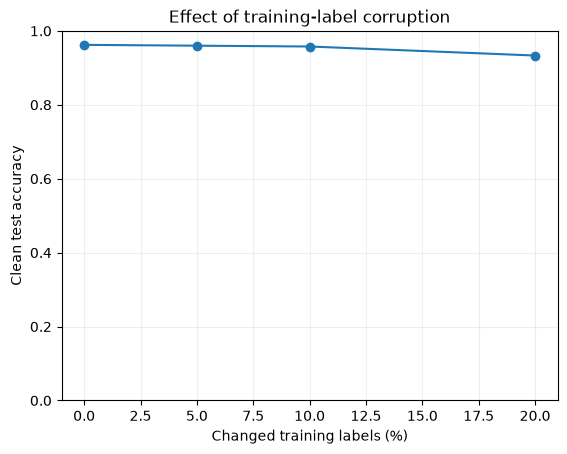

In [2]:
from sklearn.metrics import confusion_matrix
rng = np.random.default_rng(2026)
corruption_levels = [0.00, 0.05, 0.10, 0.20]
records = []
for fraction in corruption_levels:
    labels_changed = y_train.copy()
    n = round(len(labels_changed)*fraction)
    selected = rng.choice(len(labels_changed), size=n, replace=False)
    # Replace with a *different* label; this simulates integrity compromise.
    labels_changed[selected] = (labels_changed[selected] + rng.integers(1, 10, size=n)) % 10
    tested_model = build_model(X_train, labels_changed)
    accuracy = accuracy_score(y_test, tested_model.predict(X_test))
    records.append((fraction, n, accuracy))
    print(f'Corruption {fraction:.0%}: {n} labels changed | Clean test accuracy {accuracy:.3f}')
plt.plot([r[0]*100 for r in records], [r[2] for r in records], 'o-')
plt.xlabel('Changed training labels (%)'); plt.ylabel('Clean test accuracy')
plt.title('Effect of training-label corruption');plt.ylim(0,1);plt.grid(alpha=.2);plt.show()

### Part B - Create a data integrity checklist
Prepare a controls table for dataset provenance, cryptographic hashes, label audits, role-restricted writes, staged approval, and anomaly review.

**Student exercises:**
- Explain why training data is a security asset.
- Compare control results and explain any non-monotonic accuracy changes.
- Propose three technical and two procedural safeguards.

**Deliverables:** plot, results table, explanation and a signed-off integrity checklist for this hypothetical dataset.

 fraction  labels changed  accuracy  drop (pp)
       0%               0     0.962        0.0
       5%              67     0.960        0.2
      10%             135     0.958        0.4
      20%             269     0.933        2.9


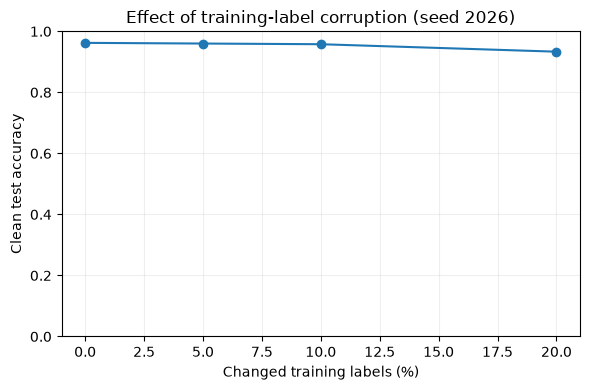

In [3]:
import os, csv
os.makedirs('../results', exist_ok=True)

rng = np.random.default_rng(2026)          # same seed as the original cell
levels = [0.00, 0.05, 0.10, 0.20]
rows = []
for f in levels:
    lab = y_train.copy()
    n = round(len(lab) * f)
    sel = rng.choice(len(lab), size=n, replace=False)
    lab[sel] = (lab[sel] + rng.integers(1, 10, size=n)) % 10
    acc = accuracy_score(y_test, build_model(X_train, lab).predict(X_test))
    rows.append((f, n, acc))

base = rows[0][2]
print(f"{'fraction':>9} {'labels changed':>15} {'accuracy':>9} {'drop (pp)':>10}")
for f, n, a in rows:
    print(f"{f:9.0%} {n:15d} {a:9.3f} {(base - a) * 100:10.1f}")

with open('../results/E03_poisoning_single_seed.csv', 'w', newline='') as fh:
    w = csv.writer(fh)
    w.writerow(['fraction', 'labels_changed', 'accuracy', 'drop_pp'])
    for f, n, a in rows:
        w.writerow([f, n, round(a, 4), round((base - a) * 100, 2)])

plt.figure(figsize=(6, 4))
plt.plot([r[0] * 100 for r in rows], [r[2] for r in rows], 'o-')
plt.xlabel('Changed training labels (%)'); plt.ylabel('Clean test accuracy')
plt.title('Effect of training-label corruption (seed 2026)')
plt.ylim(0, 1); plt.grid(alpha=.2); plt.tight_layout()
plt.savefig('../results/E03_poisoning_curve.png', dpi=200)
plt.show()

 fraction    mean      sd     min     max   per-seed
       0%   0.962   0.000   0.962   0.962   [0.962 0.962 0.962 0.962 0.962]
       5%   0.958   0.003   0.953   0.960   [0.958 0.96  0.96  0.96  0.953]
      10%   0.947   0.009   0.936   0.958   [0.958 0.944 0.936 0.942 0.953]
      20%   0.937   0.008   0.929   0.951   [0.933 0.951 0.936 0.938 0.929]


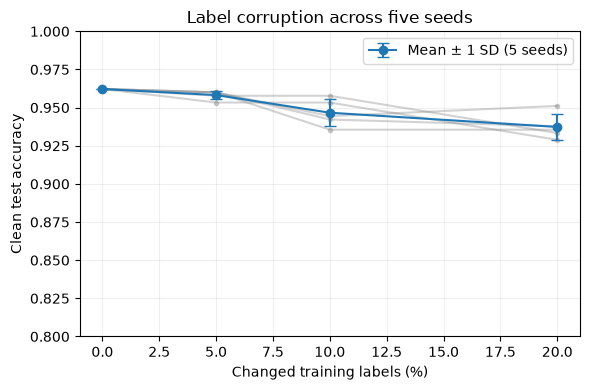

In [4]:
seeds = [1, 2, 3, 4, 5]
res = {f: [] for f in levels}
for s in seeds:
    r = np.random.default_rng(s)
    for f in levels:
        lab = y_train.copy()
        n = round(len(lab) * f)
        sel = r.choice(len(lab), size=n, replace=False)
        lab[sel] = (lab[sel] + r.integers(1, 10, size=n)) % 10
        res[f].append(accuracy_score(y_test, build_model(X_train, lab).predict(X_test)))

print(f"{'fraction':>9} {'mean':>7} {'sd':>7} {'min':>7} {'max':>7}   per-seed")
summary = []
for f in levels:
    v = np.array(res[f])
    summary.append((f, v.mean(), v.std(ddof=1), v.min(), v.max()))
    print(f"{f:9.0%} {v.mean():7.3f} {v.std(ddof=1):7.3f} {v.min():7.3f} {v.max():7.3f}   {np.round(v, 3)}")

with open('../results/E03_poisoning_multiseed.csv', 'w', newline='') as fh:
    w = csv.writer(fh)
    w.writerow(['fraction', 'mean', 'sd', 'min', 'max'] + [f'seed_{s}' for s in seeds])
    for (f, m, sd, lo, hi) in summary:
        w.writerow([f, round(m, 4), round(sd, 4), round(lo, 4), round(hi, 4)] + [round(x, 4) for x in res[f]])

fr = [s[0] * 100 for s in summary]
mn = np.array([s[1] for s in summary]); sd = np.array([s[2] for s in summary])
plt.figure(figsize=(6, 4))
for i in range(len(seeds)):
    plt.plot(fr, [res[f][i] for f in levels], color='grey', alpha=.35, marker='.')
plt.errorbar(fr, mn, yerr=sd, fmt='o-', capsize=4, label='Mean ± 1 SD (5 seeds)')
plt.legend()
plt.xlabel('Changed training labels (%)'); plt.ylabel('Clean test accuracy')
plt.title('Label corruption across five seeds')
plt.ylim(0.8, 1.0); plt.grid(alpha=.2); plt.tight_layout()
plt.savefig('../results/E03_poisoning_multiseed.png', dpi=200)
plt.show()

In [5]:
import hashlib
def sha(a):
    return hashlib.sha256(np.ascontiguousarray(a).tobytes()).hexdigest()

print('features:', sha(X_train))
print('labels  :', sha(y_train))

tampered = y_train.copy()
tampered[0] = (tampered[0] + 1) % 10
print('labels after changing ONE label:', sha(tampered))
print('hashes equal?', sha(tampered) == sha(y_train))

features: c910c3cb39438d335002b559c54256c8854b5b961734ea43976238daa3f97a5d
labels  : ee47679cf3fee7745af5763311e50ad1c1545ab1b3d15a0dd560a93cdf277f6f
labels after changing ONE label: de9550f10dd9892edf4416cf09d409173d32084fe2f113ab43e46fc7e819d9a7
hashes equal? False


In [6]:
def poison_run(C, seeds=(1, 2, 3, 4, 5)):
    out = {f: [] for f in levels}
    for s in seeds:
        r = np.random.default_rng(s)
        for f in levels:
            lab = y_train.copy()
            n = round(len(lab) * f)
            sel = r.choice(len(lab), size=n, replace=False)
            lab[sel] = (lab[sel] + r.integers(1, 10, size=n)) % 10
            m = LogisticRegression(max_iter=600, random_state=SEED, C=C).fit(X_train, lab)
            out[f].append(accuracy_score(y_test, m.predict(X_test)))
    return out

for C in [1.0, 100.0]:
    o = poison_run(C)
    print('C =', C, {f'{int(f*100)}%': round(float(np.mean(v)), 3) for f, v in o.items()})

C = 1.0 {'0%': 0.962, '5%': 0.958, '10%': 0.947, '20%': 0.937}
C = 100.0 {'0%': 0.96, '5%': 0.896, '10%': 0.888, '20%': 0.881}
